In [1]:
from ptt.io import load_full_sampler_from_filename
import torch
import h5py
import numpy as np
from rbms.dataset.utils import convert_data, get_covariance_matrix
from tqdm.autonotebook import tqdm
from rbms import load_dataset, load_params, plot_image, plot_mult_PCA
from analysis.utils import load_dataset_analysis
import matplotlib.pyplot as plt

# use LaTeX fonts in the plots
plt.rcParams.update({"font.size": 16})
plt.rcParams["text.usetex"] = True

device = "cuda"
dtype = torch.float32

/home/lorenzo/Documents/rbms/rbms/dataset/dataset_class.py:10: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


In [2]:
filename = "../models/rbm_MNIST08.h5"
train_dataset_name = "../data/MNIST08_train_bool_labeled.h5"
test_dataset_name = "../data/MNIST08_test_bool_labeled.h5"

In [3]:
train_dataset, test_dataset = load_dataset(
    dataset_name=train_dataset_name,
    test_dataset_name=test_dataset_name,
    device=device,
    dtype=dtype,
)
num_visibles = train_dataset.get_num_visibles()
num_states = train_dataset.get_num_states()

train_dataset.match_model_variable_type(
    load_params(filename, 1, device, dtype).visible_type
)
test_dataset.match_model_variable_type(
    load_params(filename, 1, device, dtype).visible_type
)

data = test_dataset.data.to(device).float()
cov_data = get_covariance_matrix(data, test_dataset.weights, device=device).float()
U_data, S_data, V_dataT = torch.linalg.svd(cov_data)

data_proj = data @ V_dataT.mT
data_proj = data_proj.cpu().numpy() / num_visibles**0.5


Reading dataset from ../data/MNIST08_train_bool_labeled.h5...
No variable_type found in the hdf5 file keys: <KeysViewHDF5 ['labels', 'samples']>. Assuming 'bernoulli'.
Set a 'variable_type' with value 'bernoulli', 'ising', 'categorical' or 'continuous' in the hdf5 archive to remove this message
    Done
Reading dataset from ../data/MNIST08_test_bool_labeled.h5...
No variable_type found in the hdf5 file keys: <KeysViewHDF5 ['labels', 'samples']>. Assuming 'bernoulli'.
Set a 'variable_type' with value 'bernoulli', 'ising', 'categorical' or 'continuous' in the hdf5 archive to remove this message
    Done


In [5]:
from rbms.utils import get_flagged_updates

num_chains = 2000
increment = 1

init_perm_chains = True

start_v = None
if init_perm_chains:
    with h5py.File(filename, "r") as f:
        start_v = torch.from_numpy(f["parallel_chains"][()]).to(
            device=device, dtype=dtype
        )

ptt_updates = get_flagged_updates(filename, "ptt")

sampler = load_full_sampler_from_filename(
    filename,
    2000,
    False,
    device,
    dtype,
    num_steps=1,
    increment=increment,
    ptt_updates=None,
)


sampler.init_annealing_chains(num_chains, 100, start_v=None)

The last ptt update '40820' does not correspond to the last saved update '50000'
Selected updates for PTT: [    1   347   362   653   697  1018  1320  1633  2013  2626  3344  4248
  5418  7068  8910 11513 15359 20979 29225 40820]


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

8 50 tensor(0.2443)
total_steps: 100; 20x tau_int: 156.33810997009277, 20x tau_exp: 543.9146905814075
New number of sampling steps: 443


  0%|          | 0/443 [00:00<?, ?it/s]

45 270 tensor(0.0929)
total_steps: 543; 20x tau_int: 199.63485717773438, 20x tau_exp: 1927.4785627758447
New number of sampling steps: 1384


  0%|          | 0/1384 [00:00<?, ?it/s]

... (5 outputs left out)

  0%|          | 0/187 [00:00<?, ?it/s]

591 tensor(3546) tensor(0.0051)
total_steps: 4994; 20x tau_int: 215.048828125, 20x tau_exp: 5156.933286944314
New number of sampling steps: 162


  0%|          | 0/162 [00:00<?, ?it/s]

591 tensor(3546) tensor(0.0051)
total_steps: 5156; 20x tau_int: 214.97940063476562, 20x tau_exp: 5152.785507701976
591 tensor(3546) tensor(0.0051)


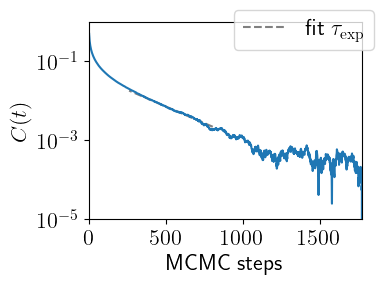

tau_int: 10.748970031738281
tau_exp: 257.6392753850988


In [6]:
# TRWAa
num_chains = 2000
tau_int, tau_exp, C = sampler.trwa(
    num_chains=num_chains, increment=increment, filename=filename, force_recompute=False
)
print(f"tau_int: {tau_int}")
print(f"tau_exp: {tau_exp}")

$\tau_\mathrm{int}$: Time to get independet samples

$\tau_\mathrm{exp}$: Time to thermalize. 20x $\tau_\mathrm{exp}$ is a safe and conservative number of MCMC steps

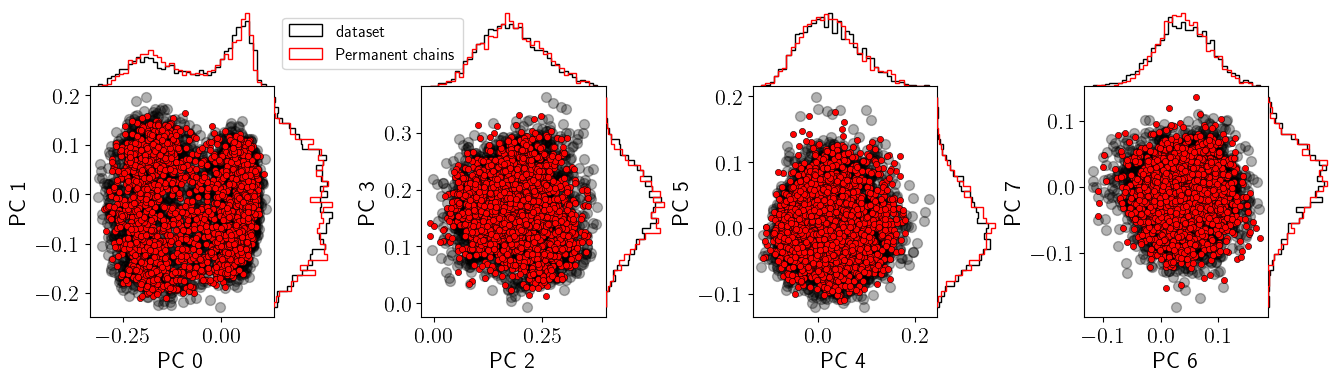

In [7]:
i = len(sampler) - 1
chains = sampler.get_chains(i)
pc_proj = chains["visible"] @ V_dataT.mT
pc_proj = pc_proj.cpu().numpy() / num_visibles**0.5

plot_mult_PCA(
    data_proj[:, :8],
    pc_proj[:, :8],
    labels=["dataset", "Permanent chains"],
)
plt.show()


# Generate large amount of samples


In [9]:
num_chains_generation = 200
num_samples_to_generate = 5000
generated_samples = sampler.sample_large(
    num_samples=num_samples_to_generate,
    num_steps_between=int(2 * tau_int + 1),
    num_steps_warmup=int(20 * tau_exp + 1),
    increment=increment,
    out_device="cpu",
    idx_model=-2,
)

  0%|          | 0/5153 [00:00<?, ?it/s]

Sample large:   0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/22 [00:00<?, ?it/s]

  0%|          | 0/22 [00:00<?, ?it/s]

In [19]:
from pathlib import Path
import h5py

model_h5 = Path(filename)
print(f"Inspecting: {model_h5.resolve()}")

with h5py.File(model_h5, "r") as f:
    update_groups = [
        k for k in f.keys()
        if "update" in k.lower() and isinstance(f[k], h5py.Group)
    ]
    update_groups = sorted(update_groups)

    print(f"Update groups found: {len(update_groups)}")

    keys_per_group = {g: sorted(list(f[g].keys())) for g in update_groups}
    unique_key_sets = sorted({tuple(v) for v in keys_per_group.values()})
    print(f"Distinct key-layouts across update groups: {len(unique_key_sets)}")

    for i, ks in enumerate(unique_key_sets, start=1):
        groups_with_layout = [g for g, v in keys_per_group.items() if tuple(v) == ks]
        print(f"\nLayout {i} ({len(ks)} keys): {list(ks)}")
        print(f"Groups with this layout: {len(groups_with_layout)}")
        print(f"Examples: {groups_with_layout[:10]}")

Inspecting: /home/lorenzo/Documents/GPSopt/models/rbm_MNIST08.h5
Update groups found: 66
Distinct key-layouts across update groups: 3

Layout 1 (16 keys): ['flags', 'hbias', 'learning_rate', 'log_z', 'numpy_rng_arg0', 'numpy_rng_arg1', 'numpy_rng_arg2', 'numpy_rng_arg3', 'numpy_rng_arg4', 'params', 'save_checkpoint', 'save_ptt', 'time', 'torch_rng_state', 'vbias', 'weight_matrix']
Groups with this layout: 1
Examples: ['update_1']

Layout 2 (15 keys): ['flags', 'hbias', 'learning_rate', 'log_z', 'numpy_rng_arg0', 'numpy_rng_arg1', 'numpy_rng_arg2', 'numpy_rng_arg3', 'numpy_rng_arg4', 'params', 'save_checkpoint', 'time', 'torch_rng_state', 'vbias', 'weight_matrix']
Groups with this layout: 46
Examples: ['update_10', 'update_1017', 'update_10992', 'update_116', 'update_1262', 'update_13', 'update_13648', 'update_145', 'update_1567', 'update_16']

Layout 3 (15 keys): ['flags', 'hbias', 'learning_rate', 'log_z', 'numpy_rng_arg0', 'numpy_rng_arg1', 'numpy_rng_arg2', 'numpy_rng_arg3', 'numpy_

# Compare overlap with Gibbs


In [10]:
model = sampler.get_model(-1)
chains = sampler.get_chains(-1)


In [12]:
num_steps = 10000
overlaps_gibbs = np.ones(num_steps * len(sampler) * increment)
overlaps_ptt = np.ones(num_steps)
init_pos_gibbs = convert_data[model.visible_type]["ising"](chains["visible"])
init_pos_ptt = convert_data[model.visible_type]["ising"](
    sampler.get_chains(-1)["visible"]
)
for i in tqdm(range(num_steps)):
    # Gibbs
    for j in range(len(sampler)):
        for k in range(increment):
            chains = model.sample_state(chains, 1)
            curr_pos_gibbs = convert_data[model.visible_type]["ising"](
                chains["visible"]
            )
            overlaps_gibbs[i * len(sampler) * increment + j * increment + k] = (
                (
                    torch.bmm(
                        init_pos_gibbs[
                            :,
                            None,
                            :,
                        ],
                        curr_pos_gibbs[:, :, None],
                    ).squeeze()
                    / curr_pos_gibbs.shape[1]
                )
                .mean()
                .item()
            )

    # PTT
    sampler.sample(1, increment=1)
    curr_pos_ptt = convert_data[model.visible_type]["ising"](
        sampler.get_chains(-1)["visible"]
    )
    overlaps_ptt[i] = (
        (
            torch.bmm(
                init_pos_ptt[
                    :,
                    None,
                    :,
                ],
                curr_pos_ptt[:, :, None],
            ).squeeze()
            / curr_pos_gibbs.shape[1]
        )
        .mean()
        .item()
    )


  0%|          | 0/10000 [00:00<?, ?it/s]

Text(0, 0.5, 'Overlap')

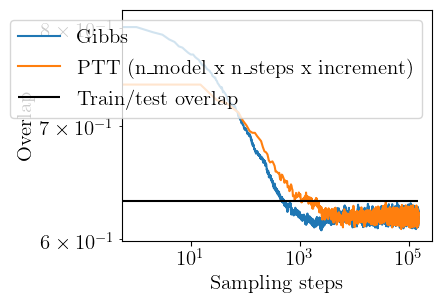

In [13]:
n_sample_test = test_dataset.data.shape[0]
n_sample_train = train_dataset.data.shape[0]
overlap_train_test = (
    torch.bmm(
        convert_data[train_dataset.variable_type]["ising"](train_dataset.data)[
            torch.randperm(n_sample_train)[:n_sample_test]
        ][
            :,
            None,
        ],
        convert_data[train_dataset.variable_type]["ising"](test_dataset.data)[
            :, :, None
        ],
    ).mean()
    / curr_pos_gibbs.shape[1]
).item()

fig, ax = plt.subplots(1, 1, figsize=(4, 3))
ax.plot(
    torch.arange(0, num_steps * len(sampler) * increment), overlaps_gibbs, label="Gibbs"
)
ax.plot(
    torch.arange(0, num_steps) * len(sampler) * increment,
    overlaps_ptt,
    label="PTT (n_model x n_steps x increment)",
)
ax.hlines(
    overlap_train_test,
    0,
    num_steps * len(sampler),
    color="black",
    label="Train/test overlap",
)

ax.loglog()
ax.legend()
ax.set_xlabel("Sampling steps")
ax.set_ylabel("Overlap")

(<Figure size 1600x1600 with 64 Axes>,
 array([[<Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >]], dtype=object))

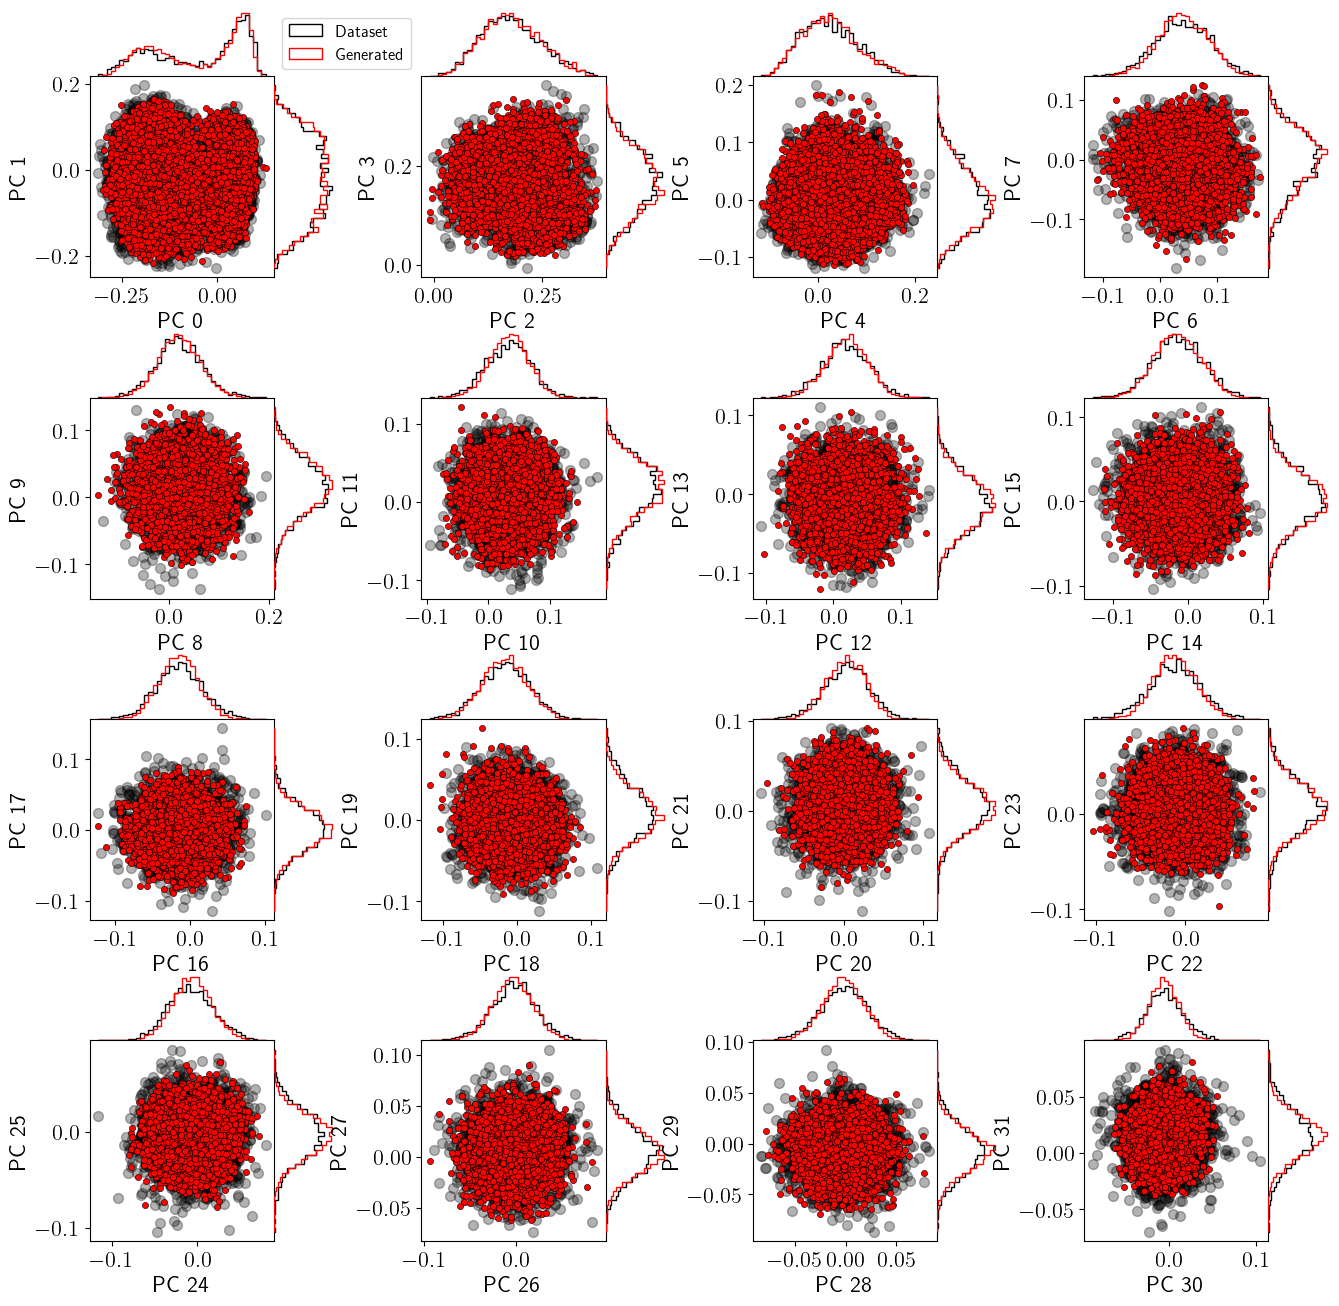

In [11]:
from rbms.custom_fn import one_hot
from rbms.plot import plot_mult_PCA

chains_to_plot = generated_samples["visible"].to(device)
pc_oh = chains_to_plot
proj_pc = pc_oh @ V_dataT.T / num_visibles**0.5


plot_mult_PCA(
    data_proj[:, :32],
    proj_pc.cpu().numpy()[:, :32],
    labels=["Dataset", "Generated"],
)

In [12]:
from analysis.correlations import compute_2b_corr
from rbms.plot import process_corr

corr_2b_test = compute_2b_corr(test_dataset.data)
corr_2b_train = compute_2b_corr(train_dataset.data)
corr_2b_ptt = compute_2b_corr(generated_samples["visible"])

/home/lorenzo/Documents/rbms/rbms/plot.py:307: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /pytorch/aten/src/ATen/native/IndexingUtils.h:37.)
  data_1 = data_1[mask]
/home/lorenzo/Documents/rbms/rbms/plot.py:308: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /pytorch/aten/src/ATen/native/IndexingUtils.h:37.)
  data_2 = data_2[mask]


Text(0.5, 0.98, 'Covariances')

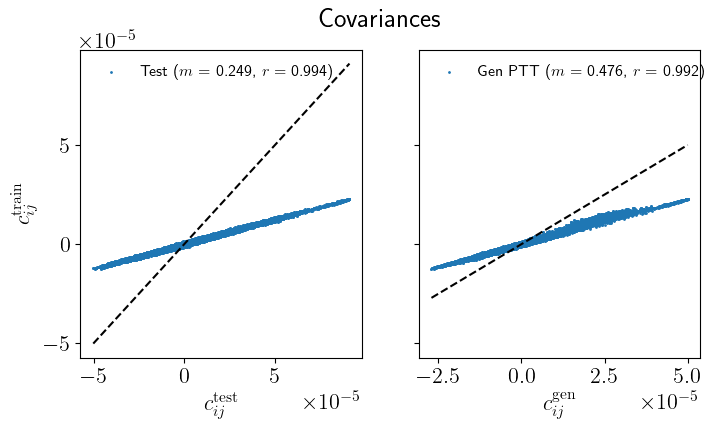

In [13]:
threshold = 0.0

fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharey=True)

m2_test, r2_test, x, y, x_line = process_corr(corr_2b_test.cpu(), corr_2b_train.cpu())
ax[0].scatter(
    x, y, s=1, label=f"Test ($m=$ {m2_test:.3f}, $r=$ {r2_test:.3f})", rasterized=True
)
ax[0].plot(x_line, x_line, "--", color="k")
ax[0].set_xlabel(r"$c_{ij}^{\mathrm{test}}$")
ax[0].set_ylabel(r"$c_{ij}^{\mathrm{train}}$")
ax[0].legend(loc="upper left", fontsize=11.5, frameon=False)

m2_pc, r2_pc, x, y, x_line = process_corr(corr_2b_ptt.cpu(), corr_2b_train.cpu())
ax[1].scatter(
    x, y, s=1, label=f"Gen PTT ($m=$ {m2_pc:.3f}, $r=$ {r2_pc:.3f})", rasterized=True
)
ax[1].plot(x_line, x_line, "--", color="k")
ax[1].set_xlabel(r"$c_{ij}^{\mathrm{gen}}$")
ax[1].legend(loc="upper left", fontsize=11.5, frameon=False)


fig.suptitle("Covariances")

In [18]:
m2_test, r2_test, x, y, x_line = process_corr(corr_2b_test.cpu(), corr_2b_ptt.cpu())


/home/lorenzo/Documents/rbms/rbms/plot.py:307: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /pytorch/aten/src/ATen/native/IndexingUtils.h:37.)
  data_1 = data_1[mask]
/home/lorenzo/Documents/rbms/rbms/plot.py:308: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /pytorch/aten/src/ATen/native/IndexingUtils.h:37.)
  data_2 = data_2[mask]


[]

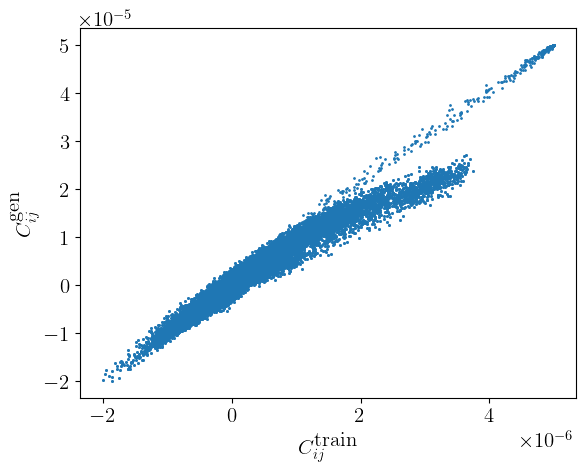

In [19]:
plt.scatter(
    corr_2b_train.flatten().cpu().numpy(),
    corr_2b_ptt.flatten().cpu().numpy(),
    s=1,
    rasterized=True,
)
plt.xlabel(r"$C_{ij}^{\textrm{train}}$")
plt.ylabel(r"$C_{ij}^{\textrm{gen}}$")
plt.plot()

[]

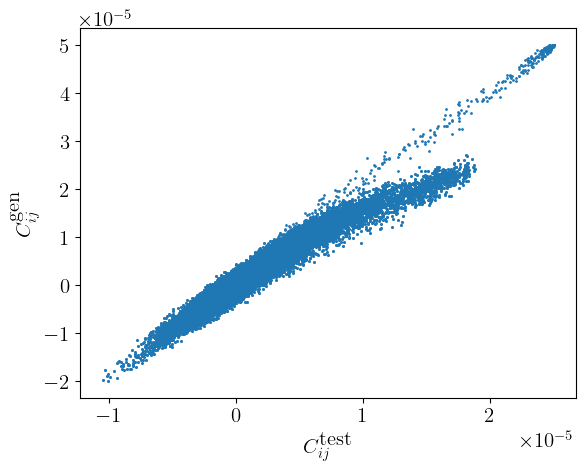

In [20]:
plt.scatter(
    corr_2b_test.flatten().cpu().numpy(),
    corr_2b_ptt.flatten().cpu().numpy(),
    s=1,
    rasterized=True,
)
plt.xlabel(r"$C_{ij}^{\textrm{test}}$")
plt.ylabel(r"$C_{ij}^{\textrm{gen}}$")
plt.plot()